# Week 6 — Computational Exercise

**1.** Price a European call using ordinary Monte Carlo and antithetic variates; compare both to Black–Scholes.  
**2.** Bootstrap the 1-day 99% Value at Risk (VaR) using approximately 10 years of S&P 500 daily returns.

The notebook uses a fixed random seed so the simulation is reproducible. Libraries: `numpy`, `pandas`, `matplotlib`, `scipy`.

## 1. European call option

Assumptions: initial stock price **$100**, strike **$100**, risk-free rate **4%**, annual volatility **20%**, maturity **1 year**. We use **20,000 total discounted payoffs for each Monte Carlo method**. The antithetic method creates 10,000 pairs of opposite random shocks. Both estimates assume the Black–Scholes risk-neutral stock-price model.

The Black–Scholes price is our benchmark. We compare standard errors, not just which estimate happens to be closest on one run.

Black-Scholes price:     $9.9251
Ordinary Monte Carlo:    $10.0183  (SE = 0.1031)
Antithetic Monte Carlo: $9.9419  (SE = 0.0745)
Estimated variance reduction: 47.8%


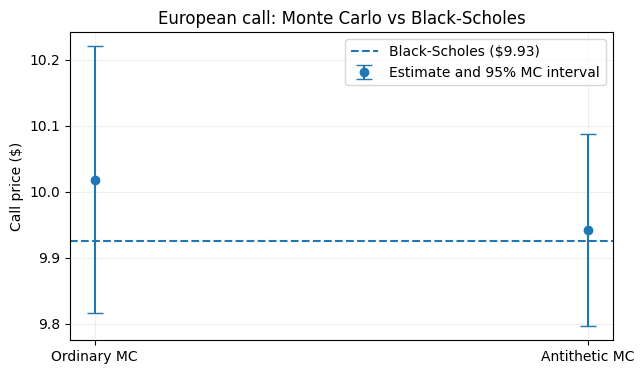

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.stats import norm

S0, K, r, sigma, T = 100, 100, 0.04, 0.20, 1
N = 20000
rng = np.random.default_rng(42)

# Analytical Black-Scholes price
d1 = (np.log(S0/K) + (r + sigma**2/2)*T) / (sigma*np.sqrt(T))
d2 = d1 - sigma*np.sqrt(T)
bs_price = S0*norm.cdf(d1) - K*np.exp(-r*T)*norm.cdf(d2)

# Discounted call payoff from a simulated standard-normal shock
def payoff(z):
    final_price = S0 * np.exp((r - sigma**2/2)*T + sigma*np.sqrt(T)*z)
    return np.exp(-r*T) * np.maximum(final_price - K, 0)

# Standard Monte Carlo: N independent payoffs
normal_payoffs = payoff(rng.standard_normal(N))
mc_price = normal_payoffs.mean()
mc_se = normal_payoffs.std(ddof=1) / np.sqrt(N)

# Antithetic Monte Carlo: N/2 pairs, using N total payoffs
z = rng.standard_normal(N//2)
paired_payoffs = (payoff(z) + payoff(-z)) / 2
anti_price = paired_payoffs.mean()
anti_se = paired_payoffs.std(ddof=1) / np.sqrt(N//2)

print(f'Black-Scholes price:     ${bs_price:.4f}')
print(f'Ordinary Monte Carlo:    ${mc_price:.4f}  (SE = {mc_se:.4f})')
print(f'Antithetic Monte Carlo: ${anti_price:.4f}  (SE = {anti_se:.4f})')
print(f'Estimated variance reduction: {100*(1-(anti_se/mc_se)**2):.1f}%')

plt.figure(figsize=(7, 4))
plt.errorbar(['Ordinary MC', 'Antithetic MC'], [mc_price, anti_price],
             yerr=1.96*np.array([mc_se, anti_se]), fmt='o', capsize=6,
             label='Estimate and 95% MC interval')
plt.axhline(bs_price, linestyle='--', label=f'Black-Scholes (${bs_price:.2f})')
plt.ylabel('Call price ($)')
plt.title('European call: Monte Carlo vs Black-Scholes')
plt.legend()
plt.grid(alpha=0.2)
plt.show()

**Interpretation.** Antithetic variates pair a positive shock with its negative, so high and low payoffs partly offset. The estimated standard error is lower than ordinary Monte Carlo with the same number of simulated payoffs. The Black–Scholes result is the theoretical benchmark under the assumed model. Antithetic variates reduce **simulation error**, but do not correct a misspecified stock-price model.

The plotted intervals show approximate 95% Monte Carlo uncertainty (estimate ± 1.96 × standard error), **not** a prediction interval for future stock prices.

## 2. S&P 500: 1-day 99% bootstrap VaR

I use **simple daily returns**, calculated as `today's closing index / previous closing index − 1`, from roughly ten years of S&P 500 closing prices. Source: [FRED, S&P 500 (SP500)](https://fred.stlouisfed.org/series/SP500), originally S&P Dow Jones Indices. The index is a **price index** (it excludes dividends).

The notebook downloads data when you run this section, so you need internet access. There is **no extra CSV file to submit**. I fix the ending date at **17 November 2026** to prevent later data changing the assignment. FRED may publish the most recent observations with a delay.

In [ ]:
# Download and calculate approximately 10 years of daily simple returns
start_date = '2016-11-17'
end_date = '2026-11-17'
url = 'https://fred.stlouisfed.org/graph/fredgraph.csv?id=SP500'

prices = pd.read_csv(url)
prices.columns = ['Date', 'Close']
prices['Date'] = pd.to_datetime(prices['Date'])
prices['Close'] = pd.to_numeric(prices['Close'], errors='coerce')
prices = prices[(prices['Date'] >= start_date) & (prices['Date'] <= end_date)]
prices = prices.dropna().sort_values('Date').set_index('Date')

returns = prices['Close'].pct_change().dropna()
if len(returns) < 2000:
    raise ValueError('Less than 8 years of daily returns downloaded; check the FRED data and dates.')

print(f'Data source: FRED SP500 (closing price index)')
print(f'Prices: {prices.index.min().date()} to {prices.index.max().date()}')
print(f'Daily return observations: {len(returns):,}')

In [ ]:
# Historical 1% quantile and bootstrap sampling uncertainty
# 99% VaR is the positive value of the negative 1st percentile return
historical_var = -np.quantile(returns, 0.01)

B = 2000  # number of bootstrap resamples
rng = np.random.default_rng(123)
boot_vars = []
for i in range(B):
    sample = rng.choice(returns.to_numpy(), size=len(returns), replace=True)
    boot_vars.append(-np.quantile(sample, 0.01))
boot_vars = np.array(boot_vars)

boot_var = boot_vars.mean()
ci_low, ci_high = np.quantile(boot_vars, [0.025, 0.975])

print(f'Historical 1-day 99% VaR: {historical_var:.2%}')
print(f'Mean bootstrapped 99% VaR: {boot_var:.2%}')
print(f'95% bootstrap confidence interval: {ci_low:.2%} to {ci_high:.2%}')
print(f'Example for $100,000: estimated 1-day VaR = ${boot_var*100000:,.0f}')

plt.figure(figsize=(8, 4))
plt.hist(returns*100, bins=65, edgecolor='white')
plt.axvline(-boot_var*100, linestyle='--', linewidth=2,
            label=f'99% bootstrap VaR: {boot_var:.2%} loss')
plt.xlabel('Daily S&P 500 return (%)')
plt.ylabel('Number of trading days')
plt.title('S&P 500 daily returns: roughly 10 years')
plt.legend()
plt.grid(alpha=0.15)
plt.show()

**Interpretation.** A 1-day 99% VaR of *X%* means that under the historical resampling model there is a 1% chance of losing more than approximately *X%* in a trading day. Use the **mean bootstrapped 99% VaR** shown above as X. The 95% bootstrap confidence interval describes **uncertainty in estimating VaR**, not a 95% interval for tomorrow's return.

Bootstrapping retains the observed shape of returns and any large historical losses, rather than imposing a normal distribution. But it cannot produce a one-day loss more extreme than the worst historical observation. Resampling days independently also ignores volatility clustering and changing market regimes, so the result should not be treated as a reliable maximum possible loss.

**Conclusion:** Monte Carlo estimates can be made more precise with antithetic variates; historical bootstrapping estimates tail risk using observed returns, but the result depends heavily on the historical sample.

*Run all cells before submitting so this section displays its numerical results and graph.*